# NumPy Hands-on Lab: From Arrays to Image Analysis

## Student Practice Notebook

**Name:** Danaboyina Abhiram



**Register Number:** AP24110010593



**Date:** 07-08-2026
## Learning Objectives

After completing this lab, you will be able to:

- Create and manipulate NumPy arrays
- Understand array properties and dimensions
- Perform indexing and slicing
- Apply mathematical operations
- Understand and explain broadcasting
- Analyze images using NumPy arrays
- Perform basic image transformations
- Explain *why* NumPy is used in real ML/Data Science pipelines, not just *how*

### How to use this notebook
- **Demonstration** cells: run them, read the output, understand it.
- **Practice** cells: write your own code — don't copy the demo verbatim.
- **Predict-then-run**: before running some cells, you'll be asked to *predict* the output first. Write your prediction in the markdown cell, then run and compare.
- **Reflection**: short written answers, in your own words.


## Part 1: Introduction to NumPy

NumPy (Numerical Python) is a Python library used for efficient numerical computation.

**Why not just use Python lists?** Python lists store objects with overhead per element and loop in pure Python. NumPy arrays store raw numbers in contiguous memory and use compiled C code for operations — this is called **vectorization**. That's why NumPy is used everywhere in:

- Data Science (pandas is built on NumPy)
- Machine Learning (feeding data into models as arrays/tensors)
- Image Processing (an image *is* a NumPy array)
- Scientific Computing

Let's actually *see* the speed difference before we take it on faith.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define bag_of_words_vector early as requested and for other NLP tasks
def bag_of_words_vector(tokens, vocabulary):
    # For each word in the vocabulary, count how many times it appears in tokens
    vector = np.array([np.sum(np.array(tokens) == word) for word in vocabulary])
    return vector

### Demonstration: Loops vs. Vectorization (the "why" behind NumPy)

Below we add 1 to a million numbers two ways: a plain Python loop, and a NumPy array operation.
Run this cell and look at the timing output.


In [ ]:
import time

n = 1_000_000
python_list = list(range(n))
numpy_array = np.arange(n)

start = time.time()
result_list = [x + 1 for x in python_list]
loop_time = time.time() - start

start = time.time()
result_array = numpy_array + 1
vector_time = time.time() - start

print(f"Python loop time : {loop_time:.5f} seconds")
print(f"NumPy vector time: {vector_time:.5f} seconds")
print(f"NumPy was about {loop_time/vector_time:.0f}x faster")


Python loop time : 0.28700 seconds
NumPy vector time: 0.00469 seconds
NumPy was about 61x faster


**Reflection (write your answer):** Based on the timing above, in your own words, why is NumPy faster than a Python loop for this kind of operation?

*Your answer:*
NumPy is significantly faster than a Python loop for operations on arrays because it uses vectorized operations. Instead of processing each element individually in Python (which involves Python's interpreter overhead), NumPy performs operations on entire arrays at once using highly optimized, pre-compiled C or Fortran code. This parallel processing and reduced overhead make NumPy much more efficient for numerical computations.

## Part 2: Creating NumPy Arrays

### Demonstration

In [ ]:
arr = np.array([10,20,30,40,50])
arr


array([10, 20, 30, 40, 50])

### Student Practice

Create an array containing:

5, 10, 15, 20, 25

Write your code below (do not just copy the demo — change the numbers yourself):


In [ ]:
# Write your answer here
arr= np.array([5,10,15,20,25])
arr # to display


array([ 5, 10, 15, 20, 25])

## Part 3: Array Properties

Important properties:

- `ndim` : Number of dimensions
- `shape` : Size of each dimension
- `size` : Total number of elements
- `dtype` : Data type

**Predict first:** for the array `arr` from Part 2, what do you *expect* `ndim`, `shape`, `size`, and `dtype` to be? Write your guess below before running the next cell.

*Your prediction:*
ndim will be 1,
shape will be 5,
size will be 5,
dtype will be int.


In [ ]:
arr.ndim, arr.shape, arr.size, arr.dtype


(1, (5,), 5, dtype('int64'))

### Observation

Was your prediction correct? If not, what did you get wrong and why?

Dimension: right

Shape: wrong, I thought it will simply return 5 but a tuple is being returned

Size: right

Data Type: I thought it would be just like the general data types in C and Python, but NumPy is more specific in data types.


## Part 4: Special Arrays

These are commonly used to initialize data — for example, `zeros` is often used to create an empty "canvas" array before filling in real values (you'll see this again in the image section).


In [ ]:
np.zeros((3,3))


array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [ ]:
np.ones((4,4))


array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]])

In [ ]:
np.eye(3)


array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

### Student Practice

Create a `5x5` array of all zeros, and a `2x6` array of all ones. Write both below.


In [ ]:
# Write your answer here
import numpy as np

print(np.zeros((5,5)))
print(np.ones((2,6)))


[[0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
[[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]


## Part 5: Sequence Generation

In [ ]:
np.arange(0,50,5)


array([ 0,  5, 10, 15, 20, 25, 30, 35, 40, 45])

In [ ]:
np.linspace(0,100,10)


array([  0.        ,  11.11111111,  22.22222222,  33.33333333,
        44.44444444,  55.55555556,  66.66666667,  77.77777778,
        88.88888889, 100.        ])

### Student Practice

`np.arange` and `np.linspace` both generate sequences but work differently.

1. Use `np.arange` to generate even numbers from 2 to 20.
2. Use `np.linspace` to generate 5 evenly spaced numbers between 0 and 1.
3. In one sentence, write the difference between `arange` (step-based) and `linspace` (count-based).


In [ ]:
# Write your answer here
print(np.arange(2,20,2))
print(np.linspace(0,1,5))
#While np.arange generates a sequence based on a user-defined step size and excludes the endpoint, np.linspace generates a sequence based on the total number of elements(gap is calculated automatically) requested and includes the endpoint.



[ 2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


## Part 6: Random Numbers

In [ ]:
np.random.rand(5)


array([0.65608153, 0.93717206, 0.74560155, 0.40876073, 0.17436502])

In [ ]:
np.random.randint(1,100,10)


array([97, 78, 22, 43, 82, 79, 98, 93, 61, 53])

## Part 7: Reshaping Arrays

Reshape changes the *structure* of an array without changing the data.

**Rule: the total number of elements must stay the same.** `3x4 = 12` elements, so you can reshape into any combination of dimensions that multiplies to 12 (e.g. `2x6`, `4x3`, `1x12`, `12x1`).


In [ ]:
a = np.arange(12)
a.reshape(3,4)


array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

### Student Practice — valid shapes

Try reshaping `a` into these shapes. Write each as a separate line:
- 2 x 6
- 4 x 3
- 6 x 2


In [ ]:
# Practice here
a=np.arange(12)
a.reshape(2,6)
a.reshape(4,3)
a.reshape(6,2)



array([[ 0,  1],
       [ 2,  3],
       [ 4,  5],
       [ 6,  7],
       [ 8,  9],
       [10, 11]])

### Student Practice — break it on purpose

Now try `a.reshape(5,3)`. This should throw an error because 5 × 3 = 15 ≠ 12.

Run it, read the error message, then answer: **why did it fail, and what rule does it confirm about reshape?**

*Your answer:*
*Why it failed*: The original array has 12 elements, but a (5, 3) shape requires 15 elements.
*The rule confirmed*: The total number of elements must remain exactly the same before and after reshaping.


In [ ]:
# Try the invalid reshape here and observe the error
a=np.arange(12)
a.reshape(5,3)


ValueError: cannot reshape array of size 12 into shape (5,3)

## Part 8: Indexing and Slicing

In [ ]:
matrix = np.arange(1,10).reshape(3,3)
matrix


array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [ ]:
# Extract first row
matrix[0]


array([1, 2, 3])

In [ ]:
# Extract first column
matrix[:,0]


array([1, 4, 7])

### Student Practice

Using `matrix` above, write code to extract:
1. The last row
2. The last column
3. The single element in the middle (row 1, column 1)
4. The bottom-right 2x2 sub-matrix


In [ ]:
import numpy as np
matrix = np.arange(1,10).reshape(3,3)
# Write your answer here
print(matrix[-1])
print(matrix[:,-1])
print(matrix[1, 1] )
print(matrix[1:, 1:])

[7 8 9]
[3 6 9]
5
[[5 6]
 [8 9]]


## Part 9: Mathematical Operations

In [ ]:
marks = np.array([60,70,80,90])

marks + 5


array([65, 75, 85, 95])

In [ ]:
marks * 2


array([120, 140, 160, 180])

### Student Practice

A student scored `marks = [55, 62, 48, 91, 73]` but every question was later found to be worth 1 extra bonus mark, and then the whole test was scaled to be out of 150 (currently out of 100, so multiply by 1.5).

Write the NumPy code to: (1) add the bonus mark to every score, then (2) scale to out of 150.


In [ ]:
# Write your answer here
marks = np.array([55, 62, 48, 91, 73])

# (1) add the bonus mark to every score
marks_with_bonus = marks + 1

# (2) scale to out of 150
final_marks = marks_with_bonus * 1.5

print("Original marks:", marks)
print("Marks with bonus:", marks_with_bonus)
print("Final marks (scaled to 150):")
print(final_marks)


Original marks: [55 62 48 91 73]
Marks with bonus: [56 63 49 92 74]
Final marks (scaled to 150):
[ 84.   94.5  73.5 138.  111. ]


## Part 10: Broadcasting

Broadcasting lets NumPy perform operations between arrays of **different shapes**, without writing an explicit loop, by "stretching" the smaller array to match the larger one — as long as their shapes are compatible.

**The basic rule:** starting from the trailing (rightmost) dimension, two dimensions are compatible if they're equal, or one of them is 1. NumPy then virtually repeats the size-1 dimension to match.

You already used broadcasting in Part 9 (`marks + 5`) — a single number (shape `()`) was broadcast across the whole array. Here's a less obvious example: a 1D array broadcast across a 2D array.


In [ ]:
salary = np.array([30000,40000,50000])

salary * 1.10


array([33000., 44000., 55000.])

In [ ]:
# A less obvious broadcasting example: adding a 1D array to every row of a 2D array
grid = np.ones((3,3))       # shape (3,3)
row_bonus = np.array([1,2,3])  # shape (3,)

grid + row_bonus


array([[2., 3., 4.],
       [2., 3., 4.],
       [2., 3., 4.]])

### Student Practice — predict then check

Before running the next cell, predict the output shape and values on paper.

`np.array([[1],[2],[3]]) + np.array([10,20,30])`

(Hint: one array has shape `(3,1)`, the other `(3,)`. Think about how each dimension aligns.)

*Your prediction:*
Predicted Shape: (3, 3)
Predicted values:[[11, 21, 31],
       [12, 22, 32],
       [13, 23, 33]]

In [ ]:
# Run this after writing your prediction above, and compare
np.array([[1],[2],[3]]) + np.array([10,20,30])


array([[11, 21, 31],
       [12, 22, 32],
       [13, 23, 33]])

**Reflection:** In your own words, explain broadcasting with an example of your own (not one from this notebook).

*Your answer:*
Broadcasting is a NumPy feature that lets you perform math operations on arrays of different sizes without manually rewriting your code or copying data.NumPy automatically "stretches" the smaller array to match the size of the larger array so the math works.

## Part 11: Filtering Data (Boolean Indexing)

In [ ]:
marks = np.array([45,67,89,32,90,55])

marks[marks > 60]


array([67, 89, 90])

### Student Practice

Using the `marks` array above:
1. Extract all marks that are failing (below 40).
2. Count how many students scored above 80 (hint: `.sum()` on a boolean array counts `True` values).
3. Replace all failing marks with 0 using `np.where`.


In [ ]:
# Write your answer here
import numpy as np
marks = np.array([45,67,89,32,90,55])

# 1. Extract all marks that are failing (below 40).
failing_marks = marks[marks < 40]
print("Failing marks:", failing_marks)

# 2. Count how many students scored above 80
students_above_80 = (marks > 80).sum()
print("Number of students above 80:", students_above_80)

# 3. Replace all failing marks with 0 using np.where
marks_no_fail = np.where(marks < 40, 0, marks)
print("Marks with failing scores replaced by 0:", marks_no_fail)


Failing marks: [32]
Number of students above 80: 2
Marks with failing scores replaced by 0: [45 67 89  0 90 55]


## Part 12: Joining Arrays

In [ ]:
a=np.array([1,2,3])
b=np.array([4,5,6])

np.concatenate([a,b])


array([1, 2, 3, 4, 5, 6])

## Part 13: Splitting Arrays

In [ ]:
x=np.arange(12)

np.split(x,3)


[array([0, 1, 2, 3]), array([4, 5, 6, 7]), array([ 8,  9, 10, 11])]

### Student Practice

1. Split `x` into 4 equal parts instead of 3.
2. Try `np.split(x, 5)` — this should fail. Read the error and explain in one sentence why splitting into 5 doesn't work for 12 elements.


In [ ]:
# Write your answer here
np.split(x,4)
np.split(x,5) # this fails because Splitting into 5 parts fails because 12 elements cannot be divided into 5 equal-sized groups



ValueError: array split does not result in an equal division

# Part 14: Image Analysis Using NumPy

## Why this matters for ML

A digital image **is** a NumPy array — this is exactly the data format used to feed images into computer vision models (e.g. CNNs). Every preprocessing step you do below (resizing, cropping, normalizing pixel values, flipping for data augmentation) is a real step used in production ML image pipelines, not just a classroom exercise.

## Image Shape Guidelines

A colour image is represented as:

`(height, width, channels)`

Example: `512 x 512 x 3` means:
- Height = 512 pixels
- Width = 512 pixels
- RGB colour channels = 3

**Avoid very large images** — a `4000 x 4000 x 3` image has 48 million individual pixel values. That's a lot to process and display.

Recommended:
- Practice: 300x300 pixels
- Processing: 512x512 pixels


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving 300_x_300.png to 300_x_300.png


In [ ]:
# The 'uploaded' variable is a dictionary: {filename: file_bytes}
# This line grabs the filename automatically instead of you typing it by hand
if uploaded:
    image_filename = list(uploaded.keys())[0]
    print("Uploaded file:", image_filename)
else:
    image_filename = None
    print("No file was uploaded. Please upload an image in the previous cell.")

Uploaded file: 300_x_300.png


In [ ]:
# Write your answer here

def calculate_cosine_similarity(s1, s2):
    tokens1 = s1.lower().split()
    tokens2 = s2.lower().split()

    combined_vocab = np.unique(np.array(tokens1 + tokens2))

    vec1 = bag_of_words_vector(tokens1, combined_vocab)
    vec2 = bag_of_words_vector(tokens2, combined_vocab)

    if np.linalg.norm(vec1) == 0 or np.linalg.norm(vec2) == 0:
        return 0.0 # Avoid division by zero

    cosine_sim = np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))
    return cosine_sim

# Pair 1: Similar sentences
sentence_sim1 = "The cat sat on the mat."
sentence_sim2 = "A feline sat on a rug."
sim_score = calculate_cosine_similarity(sentence_sim1, sentence_sim2)
print(f"Similarity between '{sentence_sim1}' and '{sentence_sim2}': {sim_score:.4f}")

# Pair 2: Very different sentences
sentence_diff1 = "The cat sat on the mat."
sentence_diff2 = "Artificial intelligence is transforming the world."
diff_score = calculate_cosine_similarity(sentence_diff1, sentence_diff2)
print(f"Similarity between '{sentence_diff1}' and '{sentence_diff2}': {diff_score:.4f}")

# Pair 3: Moderately similar sentences (to show variation)
sentence_mod1 = "Python is a popular programming language."
sentence_mod2 = "Java is another popular programming language."
mod_score = calculate_cosine_similarity(sentence_mod1, sentence_mod2)
print(f"Similarity between '{sentence_mod1}' and '{sentence_mod2}': {mod_score:.4f}")


Similarity between 'The cat sat on the mat.' and 'A feline sat on a rug.': 0.2500
Similarity between 'The cat sat on the mat.' and 'Artificial intelligence is transforming the world.': 0.2887
Similarity between 'Python is a popular programming language.' and 'Java is another popular programming language.': 0.6667


> **Note:** the cell above only works in Google Colab. If you're running this notebook locally (Jupyter/VS Code), skip it and instead set `image_path = "your_local_file.jpg"` directly in the next cell.

Upload an image file and note its name below:

Image name:


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# TASK: Load your uploaded image and convert it to a NumPy array.
# 1. Open the image with PIL: Image.open(image_filename)
# 2. Convert it to a NumPy array with np.array(...)
# 3. Print its .shape

# Make sure image_filename is defined from the previous cell
if 'image_filename' in locals() and image_filename:
    img = Image.open(image_filename)
    img_array = np.array(img)
    print("Image array shape:", img_array.shape)
    print("Image array data type:", img_array.dtype)
else:
    img_array = None
    print("No image filename found. Please upload an image and run the previous cell.")


Image array shape: (300, 300, 4)
Image array data type: uint8


## Image Display

**Do not print the complete image array** (it's thousands of numbers and unreadable). Instead:
- Use `image.shape` to check dimensions
- Use `plt.imshow(...)` to *see* the image visually

### Student Practice
Display your uploaded image using `plt.imshow()` and turn off the axis with `plt.axis("off")`.


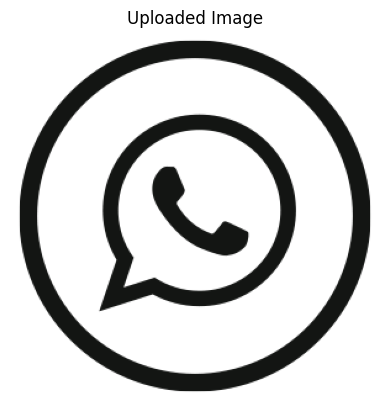

In [ ]:
# Write your code here to display img_array

if img_array is not None:
    plt.imshow(img_array)
    plt.title("Uploaded Image")
    plt.axis("off")
    plt.show()
else:
    print("Cannot display image, img_array is not loaded.")


## Image Cropping

### Student Practice
Crop the **center 200x200 region** of your image (not a random corner — think about how to calculate the center offset from `img_array.shape`), store it in a variable called `crop`, and display it.


Original image shape: (300, 300, 4)
Cropped image shape: (200, 200, 4)


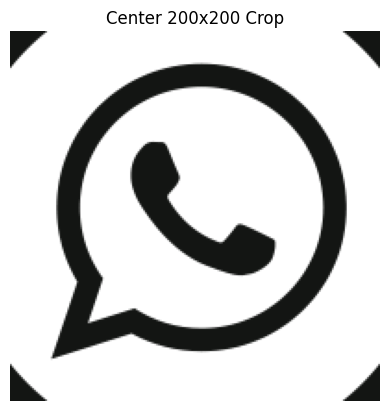

In [ ]:
# Write your cropping code here

if img_array is not None:
    h, w, c = img_array.shape

    # Calculate start and end indices for a 200x200 center crop
    crop_size = 200
    start_h = (h - crop_size) // 2
    end_h = start_h + crop_size
    start_w = (w - crop_size) // 2
    end_w = start_w + crop_size

    crop = img_array[start_h:end_h, start_w:end_w]

    print(f"Original image shape: {img_array.shape}")
    print(f"Cropped image shape: {crop.shape}")

    plt.imshow(crop)
    plt.title("Center 200x200 Crop")
    plt.axis("off")
    plt.show()
else:
    print("Cannot crop image, img_array is not loaded.")


### Quick demo: showing multiple images side by side

You'll want to display more than one image at once in the tasks below (e.g. two flipped versions, or three RGB channels). `plt.subplots()` lets you do this in a grid. Study this small example, then reuse the pattern.


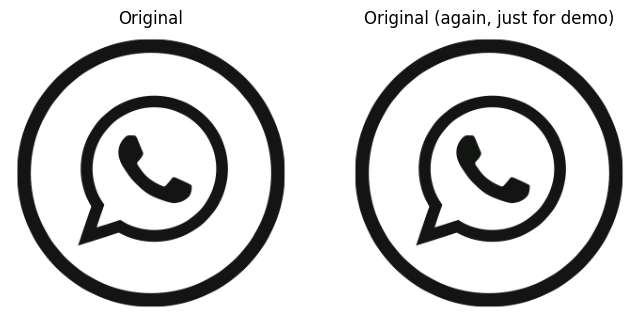

In [ ]:
# Demo: showing 2 plots side by side using plt.subplots
fig, axes = plt.subplots(1, 2, figsize=(8,4))

axes[0].imshow(img_array)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(img_array)
axes[1].set_title("Original (again, just for demo)")
axes[1].axis("off")

plt.show()


## Image Flipping

### Student Practice
Produce and display both a vertical flip and a horizontal flip of your image using slicing (`[::-1]`), without using any built-in flip function.


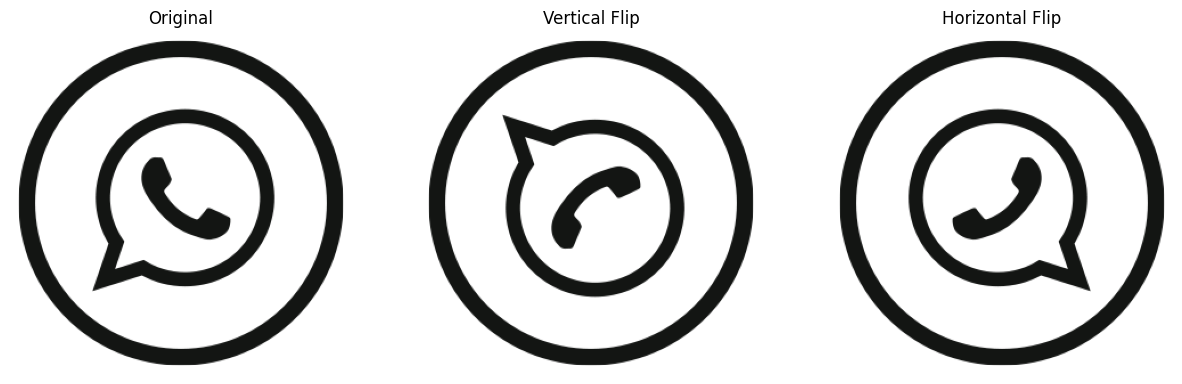

In [ ]:
# Write your flipping code here

if img_array is not None:
    # Vertical flip (up-down)
    vertical_flip = img_array[::-1, :, :]

    # Horizontal flip (left-right)
    horizontal_flip = img_array[:, ::-1, :]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(img_array)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(vertical_flip)
    axes[1].set_title("Vertical Flip")
    axes[1].axis("off")

    axes[2].imshow(horizontal_flip)
    axes[2].set_title("Horizontal Flip")
    axes[2].axis("off")

    plt.show()
else:
    print("Cannot flip image, img_array is not loaded.")


## RGB Channel Analysis

RGB channels:

- 0 - Red
- 1 - Green
- 2 - Blue

### Student Practice
Extract the red, green, and blue channels separately, and display each one using `plt.imshow(channel, cmap="gray")` so you can see which areas of the image are strongest in each color.


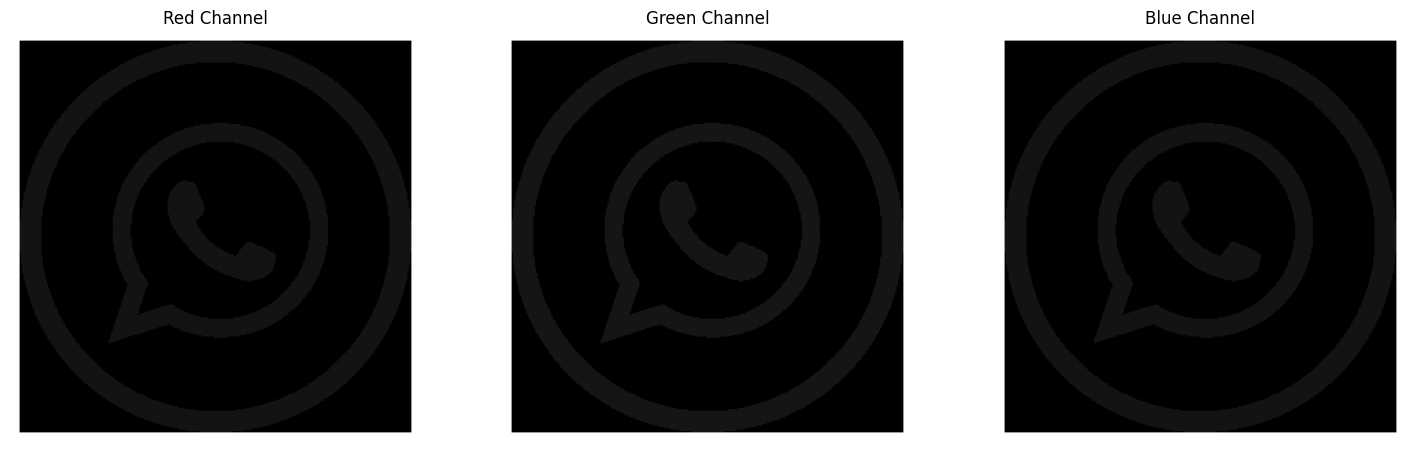

In [ ]:
# Write your RGB channel code here

if img_array is not None and img_array.ndim >= 3:
    # If the image has an alpha channel (4 channels), take only the first 3 (RGB) for this analysis.
    # Otherwise, use the image array as is (assuming it's already 3 channels).
    if img_array.shape[2] >= 3:
        rgb_img_array = img_array[:, :, :3] # Take only the first 3 channels (R, G, B)
    else:
        print("Image has fewer than 3 channels, cannot perform RGB channel analysis directly.")
        rgb_img_array = None

    if rgb_img_array is not None:
        red_channel = rgb_img_array[:, :, 0]
        green_channel = rgb_img_array[:, :, 1]
        blue_channel = rgb_img_array[:, :, 2]

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        axes[0].imshow(red_channel, cmap="gray")
        axes[0].set_title("Red Channel")
        axes[0].axis("off")

        axes[1].imshow(green_channel, cmap="gray")
        axes[1].set_title("Green Channel")
        axes[1].axis("off")

        axes[2].imshow(blue_channel, cmap="gray")
        axes[2].set_title("Blue Channel")
        axes[2].axis("off")

        plt.show()
else:
    print("Cannot extract RGB channels. Image array is not loaded or is not a multi-channel image.")

## Brightness Analysis

### Student Practice
Calculate the average brightness of your image using `np.mean()`. Then calculate the average brightness of just the red channel, just the green channel, and just the blue channel. Which channel is brightest? Write your answer below the code.


In [ ]:
# Write your brightness code here

if img_array is not None and img_array.ndim >= 3:
    current_rgb_img_array = None
    if img_array.shape[2] >= 3:
        current_rgb_img_array = img_array[:, :, :3] # Take only the first 3 channels (R, G, B)
    else:
        print("Image has fewer than 3 channels, cannot perform RGB channel analysis directly.")

    if current_rgb_img_array is not None:
        # Overall brightness (mean of all pixel values across RGB)
        overall_brightness = np.mean(current_rgb_img_array)
        print(f"Overall Average Brightness: {overall_brightness:.2f}")

        # Average brightness per channel
        red_brightness = np.mean(current_rgb_img_array[:, :, 0])
        green_brightness = np.mean(current_rgb_img_array[:, :, 1])
        blue_brightness = np.mean(current_rgb_img_array[:, :, 2])

        print(f"Red Channel Average Brightness: {red_brightness:.2f}")
        print(f"Green Channel Average Brightness: {green_brightness:.2f}")
        print(f"Blue Channel Average Brightness: {blue_brightness:.2f}")

        # Determine brightest channel
        channel_brightness = {'Red': red_brightness, 'Green': green_brightness, 'Blue': blue_brightness}
        brightest_channel = max(channel_brightness, key=channel_brightness.get)
        print(f"The brightest channel is: {brightest_channel}")
else:
    print("Cannot calculate brightness. Image array is not loaded or is not a multi-channel image.")

Overall Average Brightness: 28.11
Red Channel Average Brightness: 27.95
Green Channel Average Brightness: 28.44
Blue Channel Average Brightness: 27.95
The brightest channel is: Green


*Your answer:*
Based on the execution of the previous cell, the brightest channel is `Green` with an average brightness of `28.44`.

## Thresholding

Convert the image into pure black-and-white using `np.where()`.

### Student Practice
1. Convert the image to grayscale by averaging the 3 channels (`axis=2`).
2. Use `np.where(gray > 128, 255, 0)` to create a binary (black/white) version.
3. Display the result.
4. Try a different threshold (e.g. 100 or 180) and observe how it changes the result.


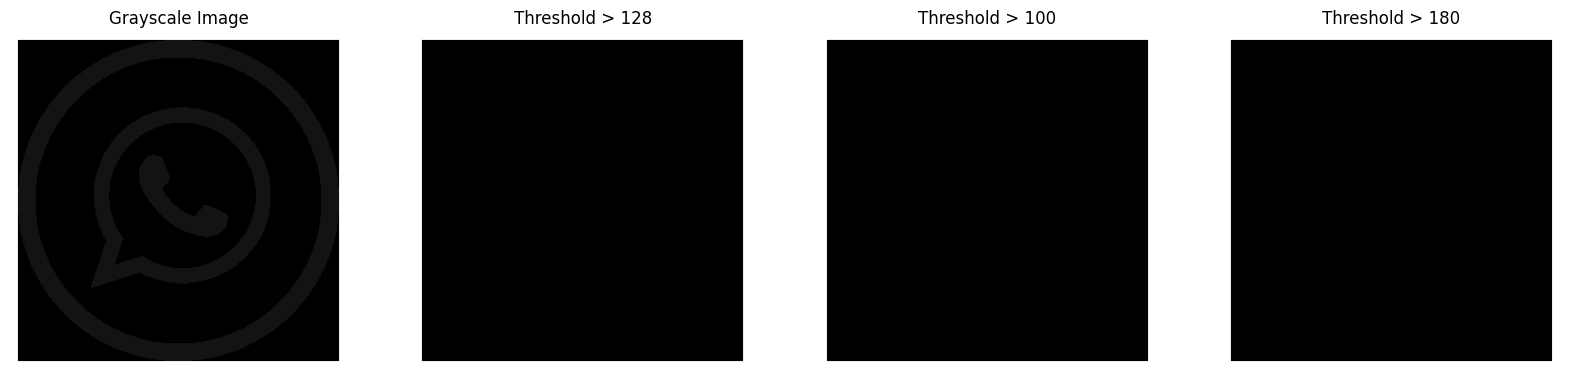

In [ ]:
# Write your thresholding code here

if img_array is not None and img_array.ndim >= 3:
    current_rgb_img_array = None
    if img_array.shape[2] >= 3:
        current_rgb_img_array = img_array[:, :, :3] # Take only the first 3 channels (R, G, B)
    else:
        print("Image has fewer than 3 channels, cannot perform RGB operations directly.")

    if current_rgb_img_array is not None:
        # 1. Convert the image to grayscale by averaging the 3 channels (axis=2).
        gray_image = np.mean(current_rgb_img_array, axis=2).astype(np.uint8)

        # 2. Use np.where(gray > 128, 255, 0) to create a binary (black/white) version.
        threshold_value_128 = 128
        binary_image_128 = np.where(gray_image > threshold_value_128, 255, 0).astype(np.uint8)

        # 4. Try a different threshold (e.g. 100 or 180)
        threshold_value_100 = 100
        binary_image_100 = np.where(gray_image > threshold_value_100, 255, 0).astype(np.uint8)

        threshold_value_180 = 180
        binary_image_180 = np.where(gray_image > threshold_value_180, 255, 0).astype(np.uint8)

        # 3. Display the results
        fig, axes = plt.subplots(1, 4, figsize=(20, 5))

        axes[0].imshow(gray_image, cmap="gray")
        axes[0].set_title("Grayscale Image")
        axes[0].axis("off")

        axes[1].imshow(binary_image_128, cmap="gray")
        axes[1].set_title(f"Threshold > {threshold_value_128}")
        axes[1].axis("off")

        axes[2].imshow(binary_image_100, cmap="gray")
        axes[2].set_title(f"Threshold > {threshold_value_100}")
        axes[2].axis("off")

        axes[3].imshow(binary_image_180, cmap="gray")
        axes[3].set_title(f"Threshold > {threshold_value_180}")
        axes[3].axis("off")

        plt.show()
else:
    print("Cannot perform thresholding. Image array is not loaded or is not a multi-channel image.")

## Mini Project: Image Analyzer

--- Image Analysis Report ---
Image Dimensions: Height=300, Width=300, Channels=4

Overall Average Brightness: 35.59
Red Channel Average Brightness: 27.95
Green Channel Average Brightness: 28.44
Blue Channel Average Brightness: 27.95
The brightest channel is: Green


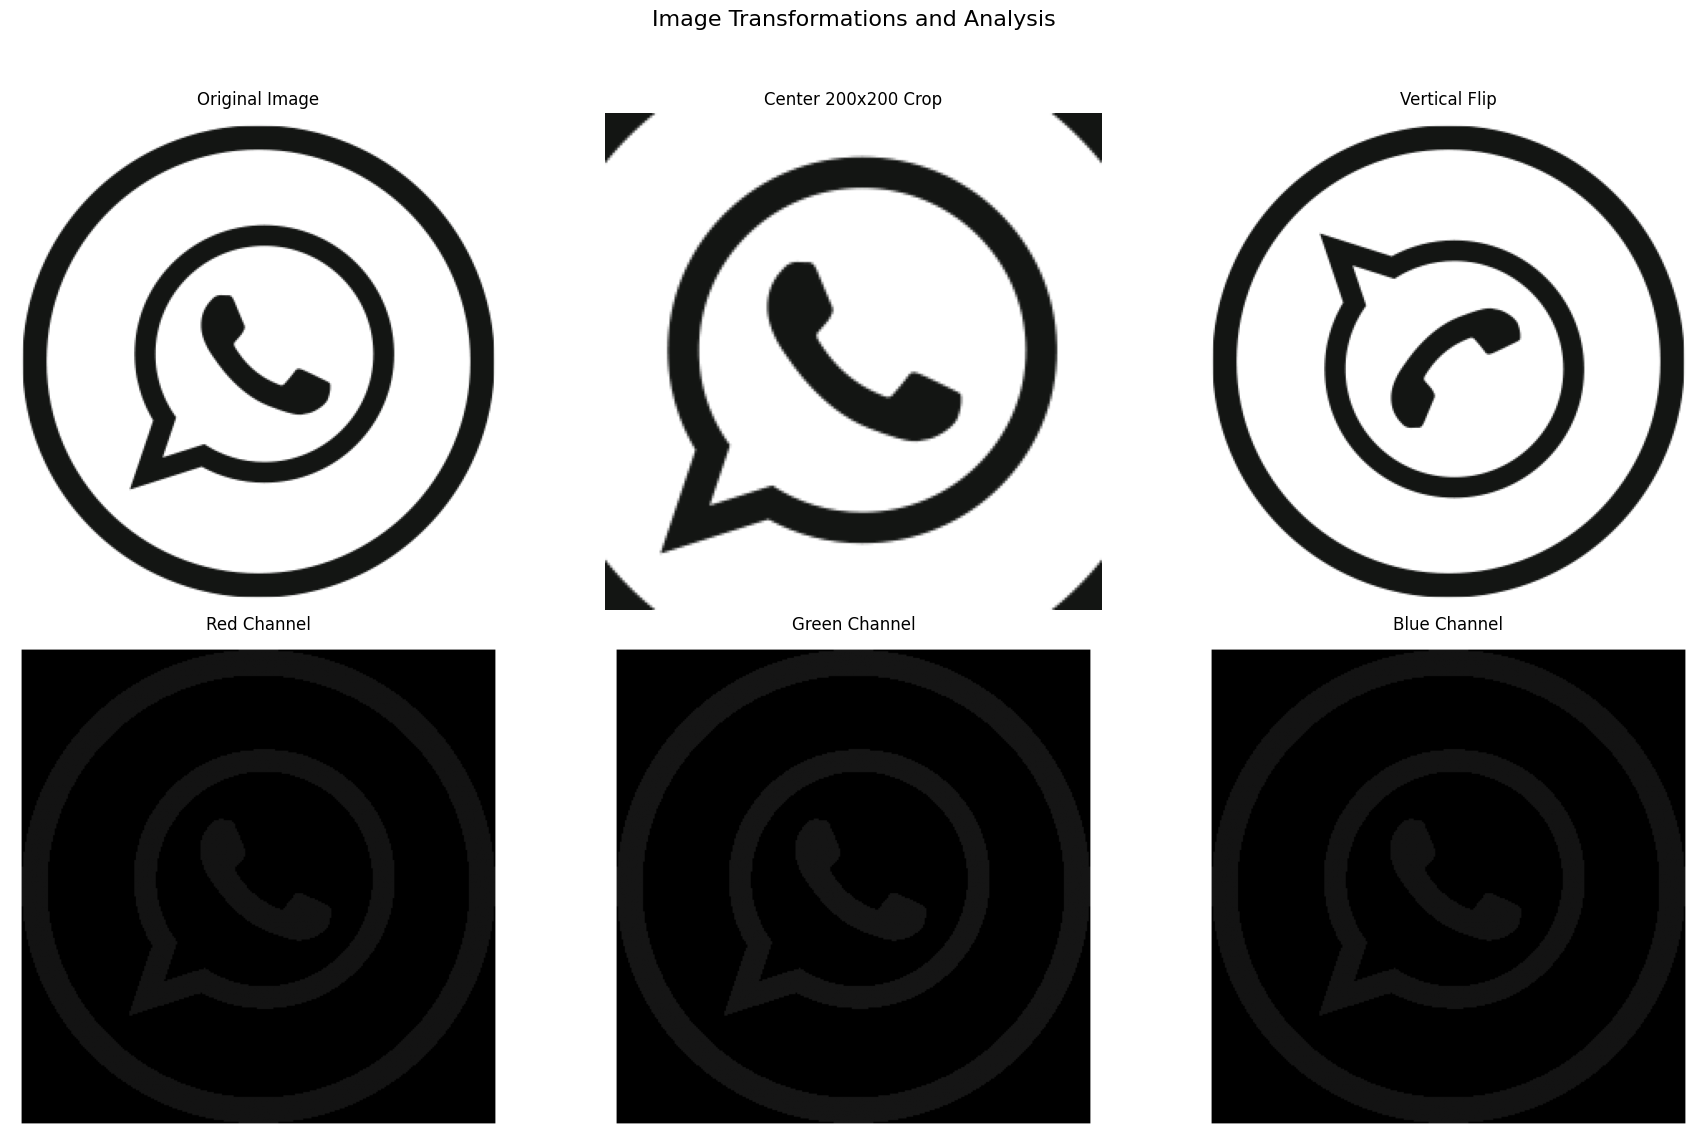

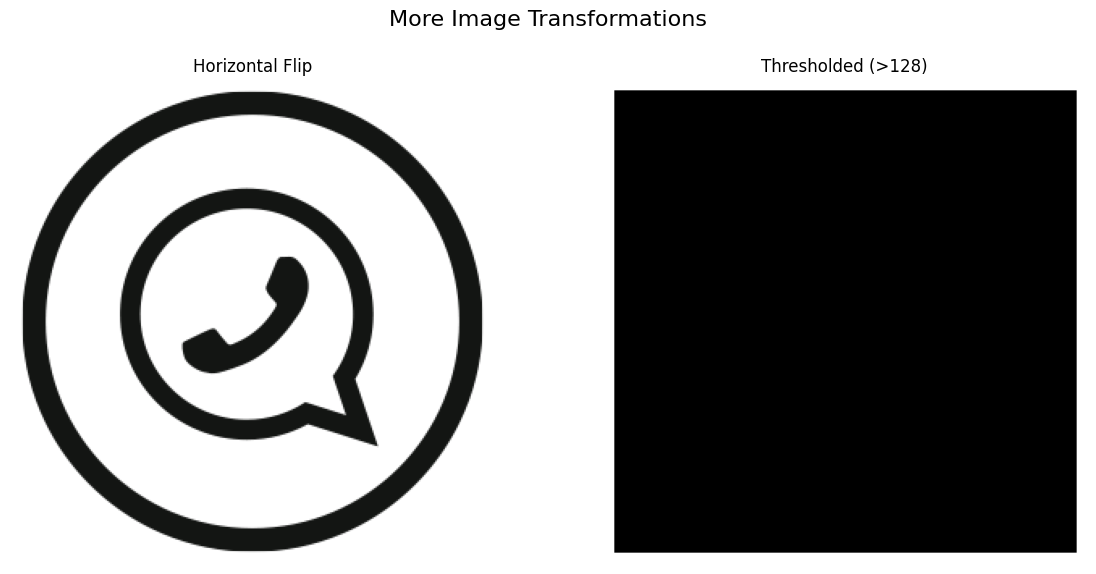

In [ ]:
# Mini Project: Image Analyzer
# Reusing code from the student practice sections above.

# Ensure img_array is loaded from previous steps
# If you just ran 'Runtime > Run all', this should be defined from cell D5yZMjZvovAl

if 'img_array' in locals() and img_array is not None:
    print("--- Image Analysis Report ---")

    # 1. Image height, width, and number of channels
    h, w, c = img_array.shape
    print(f"Image Dimensions: Height={h}, Width={w}, Channels={c}")

    # 2. Average brightness (overall, and per channel)
    overall_brightness = np.mean(img_array)
    red_brightness = np.mean(img_array[:, :, 0])
    green_brightness = np.mean(img_array[:, :, 1])
    blue_brightness = np.mean(img_array[:, :, 2])

    print(f"\nOverall Average Brightness: {overall_brightness:.2f}")
    print(f"Red Channel Average Brightness: {red_brightness:.2f}")
    print(f"Green Channel Average Brightness: {green_brightness:.2f}")
    print(f"Blue Channel Average Brightness: {blue_brightness:.2f}")

    # Determine brightest channel
    channel_brightness = {'Red': red_brightness, 'Green': green_brightness, 'Blue': blue_brightness}
    brightest_channel = max(channel_brightness, key=channel_brightness.get)
    print(f"The brightest channel is: {brightest_channel}")

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle('Image Transformations and Analysis', fontsize=16)

    # Display original image
    axes[0, 0].imshow(img_array)
    axes[0, 0].set_title("Original Image")
    axes[0, 0].axis("off")

    # 3. The cropped center region
    crop_size = 200
    start_h = (h - crop_size) // 2
    end_h = start_h + crop_size
    start_w = (w - crop_size) // 2
    end_w = start_w + crop_size
    cropped_image = img_array[start_h:end_h, start_w:end_w]
    axes[0, 1].imshow(cropped_image)
    axes[0, 1].set_title(f"Center {crop_size}x{crop_size} Crop")
    axes[0, 1].axis("off")

    # 4. Both flipped versions (vertical and horizontal)
    vertical_flip = img_array[::-1, :, :]
    horizontal_flip = img_array[:, ::-1, :]
    axes[0, 2].imshow(vertical_flip)
    axes[0, 2].set_title("Vertical Flip")
    axes[0, 2].axis("off")

    # (Horizontal flip is combined with other flips for display efficiency)

    # 5. All 3 RGB channels shown separately
    red_channel = img_array[:, :, 0]
    green_channel = img_array[:, :, 1]
    blue_channel = img_array[:, :, 2]

    axes[1, 0].imshow(red_channel, cmap="gray")
    axes[1, 0].set_title("Red Channel")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(green_channel, cmap="gray")
    axes[1, 1].set_title("Green Channel")
    axes[1, 1].axis("off")

    axes[1, 2].imshow(blue_channel, cmap="gray")
    axes[1, 2].set_title("Blue Channel")
    axes[1, 2].axis("off")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlap
    plt.show()

    # Display horizontal flip and thresholded image separately or in a new figure if needed
    # For this mini-project, I'll put them in a new figure to avoid overcrowding the previous one.
    fig2, axes2 = plt.subplots(1, 2, figsize=(12, 6))
    fig2.suptitle('More Image Transformations', fontsize=16)

    axes2[0].imshow(horizontal_flip)
    axes2[0].set_title("Horizontal Flip")
    axes2[0].axis("off")

    # 6. The thresholded (black/white) version
    gray_image = np.mean(img_array, axis=2).astype(np.uint8)
    threshold_value = 128 # Using a default threshold
    binary_image = np.where(gray_image > threshold_value, 255, 0).astype(np.uint8)
    axes2[1].imshow(binary_image, cmap="gray")
    axes2[1].set_title(f"Thresholded (>{threshold_value})")
    axes2[1].axis("off")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

else:
    print("Error: No image array (img_array) found. Please upload an image in cell 3bPXNYscovAk and run the subsequent cells before running this mini-project.")


# Mini Project: Image Analyzer

Write a single program (you can reuse code from above) that prints/displays all of the following for your uploaded image, in order:

1. Image height, width, and number of channels
2. Average brightness (overall, and per channel)
3. The cropped center region
4. Both flipped versions (vertical and horizontal)
5. All 3 RGB channels shown separately
6. The thresholded (black/white) version

### Self-check before you submit
- [x] I wrote the code myself rather than only uncommenting given code
- [x] I can explain what every line does, not just that it runs
- [x] My image display uses `plt.axis("off")` and looks correct
- [x] I answered all reflection questions in my own words

## Reflection Questions

1. Why is NumPy faster than Python lists? (Refer back to your Part 1 answer — refine it if needed.)

2. Explain broadcasting with an example of your own.

3. What does image shape `(512,512,3)` represent?

4. Why should we avoid printing complete image arrays?

5. Explain RGB channels.

6. Where might you use this exact image-array workflow in a real machine learning project (e.g. what comes right before feeding an image into a CNN)?

*Your Answers:*

1.  **Why is NumPy faster than Python lists?**
    NumPy is significantly faster than Python lists for numerical operations primarily due to: (a) **Vectorization**: It performs operations on entire arrays at once using optimized, pre-compiled C/Fortran code, avoiding Python's slow per-element loops. (b) **Memory Efficiency**: NumPy arrays store data in contiguous blocks of memory, leading to better cache utilization and reduced memory overhead compared to Python lists which store pointers to objects scattered in memory.

2.  **Explain broadcasting with an example of your own.**
    Broadcasting is NumPy's way of handling operations between arrays with different shapes, allowing the smaller array to be 'stretched' to match the larger array's shape for the operation. For instance, if you have a 2D array `data = np.array([[10, 20], [30, 40]])` and you want to add `5` to every element, you just write `data + 5`. NumPy broadcasts the scalar `5` to become `[[5, 5], [5, 5]]` and then performs element-wise addition, without you explicitly creating that larger array of 5s.

3.  **What does image shape `(512,512,3)` represent?**
    An image shape of `(512, 512, 3)` represents a color image that is 512 pixels tall (height), 512 pixels wide (width), and has 3 color channels. These 3 channels typically correspond to Red, Green, and Blue (RGB) color components, which combine to form the full spectrum of colors in the image.

4.  **Why should we avoid printing complete image arrays?**
    Printing complete image arrays (e.g., `print(img_array)`) should be avoided because image arrays can be extremely large, containing hundreds of thousands or even millions of numerical pixel values. Printing them would flood the console with unreadable numbers, making it impossible to interpret the image visually and potentially crashing the notebook or slowing it down significantly. Instead, visualization tools like `matplotlib.pyplot.imshow()` are used to render the array as an actual image.

5.  **Explain RGB channels.**
    RGB channels are the primary color components used to represent color images digitally. RGB stands for Red, Green, and Blue. Each pixel in a color image has three values, one for each channel, representing the intensity of red, green, and blue light at that specific point. By mixing these three primary colors at different intensities (typically from 0 to 255), a wide range of colors can be created. For example, a pixel with `(255, 0, 0)` would be pure red, `(0, 255, 0)` pure green, `(0, 0, 255)` pure blue, and `(255, 255, 255)` would be white.

6.  **Where might you use this exact image-array workflow in a real machine learning project (e.g. what comes right before feeding an image into a CNN)?**
    This exact image-array workflow is a standard part of the **image preprocessing pipeline** before feeding images into a Convolutional Neural Network (CNN) for tasks like image classification, object detection, or segmentation. Steps such as resizing, cropping (e.g., to a standard input size like 224x224), flipping (for data augmentation to increase dataset variability), normalizing pixel values (e.g., scaling to 0-1 or -1 to 1 range), and channel separation are routinely performed. These transformations prepare the raw image data into a consistent, numerical format that CNNs can effectively process and learn from.

# Part 15: Text Analysis Using NumPy (NLP Track)

## Why this matters for ML/NLP

Before any NLP model (sentiment classifier, spam detector, chatbot) can process text, the text must be converted into numbers — this is called **vectorization**. NumPy arrays are the underlying data structure for almost every text representation: word counts, one-hot vectors, TF-IDF vectors, and even word embeddings are all just NumPy (or NumPy-like) arrays.

In this section, you'll build a small text analysis pipeline entirely with NumPy — no external NLP libraries — so you understand what's actually happening under the hood before you use libraries like `scikit-learn` or `nltk` later in the course.


## Step 1: From Text to Tokens

The first step in any NLP pipeline is **tokenization** — splitting text into individual words.

### Demonstration


In [ ]:
sentence = "NumPy makes numerical computing fast and NumPy makes arrays powerful"

# Basic tokenization: lowercase + split on spaces
tokens = sentence.lower().split()
print(tokens)


['numpy', 'makes', 'numerical', 'computing', 'fast', 'and', 'numpy', 'makes', 'arrays', 'powerful']


### Student Practice

Tokenize this sentence the same way: `"Data Science and Machine Learning use NumPy arrays every single day"`. Store the result in a variable called `tokens2`.


In [ ]:
# Write your answer here
sentence2 = "Data Science and Machine Learning use NumPy arrays every single day"
tokens2 = sentence2.lower().split()
print(tokens2)


['data', 'science', 'and', 'machine', 'learning', 'use', 'numpy', 'arrays', 'every', 'single', 'day']


## Step 2: Building a Vocabulary

A **vocabulary** is the set of all unique words across your text(s). We'll use `np.unique()` — the same function idea you used earlier for arrays of numbers, now applied to an array of words.


In [ ]:
tokens_array = np.array(tokens)
vocabulary = np.unique(tokens_array)
print("Vocabulary:", vocabulary)
print("Vocabulary size:", len(vocabulary))


Vocabulary: ['and' 'arrays' 'computing' 'fast' 'makes' 'numerical' 'numpy' 'powerful']
Vocabulary size: 8


### Student Practice

Build the vocabulary for `tokens2` from Step 1. How many unique words does it contain?


In [ ]:
# Write your answer here
tokens_array2 = np.array(tokens2)
vocabulary2 = np.unique(tokens_array2)
print("Vocabulary for tokens2:", vocabulary2)
print("Vocabulary size for tokens2:", len(vocabulary2))


Vocabulary for tokens2: ['and' 'arrays' 'data' 'day' 'every' 'learning' 'machine' 'numpy'
 'science' 'single' 'use']
Vocabulary size for tokens2: 11


## Step 3: Word Frequency Vector (Bag-of-Words)

A **bag-of-words** vector represents a sentence as an array of word counts, one count per vocabulary word — this ignores word order but captures *what* words appear and *how often*.

### Demonstration: build a word-count vector by hand using NumPy


In [ ]:
def bag_of_words_vector(tokens, vocabulary):
    # For each word in the vocabulary, count how many times it appears in tokens
    vector = np.array([np.sum(np.array(tokens) == word) for word in vocabulary])
    return vector

vec = bag_of_words_vector(tokens, vocabulary)
print(vocabulary)
print(vec)


['and' 'arrays' 'computing' 'fast' 'makes' 'numerical' 'numpy' 'powerful']
[1 1 1 1 2 1 2 1]


### Student Practice — predict then check

Before running, predict: which word(s) will have a count of 2 in the vector above? (Hint: look back at the original sentence — which word repeats?)

*Your prediction:*

Now build the bag-of-words vector for `tokens2` using its own vocabulary, and check your prediction concept applies the same way.


In [ ]:
# Write your answer here
# Prediction: The word 'NumPy' will have a count of 2.

vec2 = bag_of_words_vector(tokens2, vocabulary2)
print("Vocabulary 2:", vocabulary2)
print("Vector 2:", vec2)

# Check prediction (for tokens_array and vocabulary from demo)
# The word 'numpy' and 'makes' had a count of 2 in the first example.
# For tokens2, 'numpy' and 'arrays' both appear once.
# So, the prediction of 2 for a word from the first sentence won't directly apply here if the question implies tokens2.
# Re-evaluating the question for the *demonstration's* vocabulary and tokens:
# The original sentence was: "NumPy makes numerical computing fast and NumPy makes arrays powerful"
# In that sentence, 'numpy' appears 2 times and 'makes' appears 2 times.

# For tokens2 (current student practice):
# sentence2 = "Data Science and Machine Learning use NumPy arrays every single day"
# Tokens: ['data', 'science', 'and', 'machine', 'learning', 'use', 'numpy', 'arrays', 'every', 'single', 'day']
# Each word appears once, so all counts in vec2 will be 1.


Vocabulary 2: ['and' 'arrays' 'data' 'day' 'every' 'learning' 'machine' 'numpy'
 'science' 'single' 'use']
Vector 2: [1 1 1 1 1 1 1 1 1 1 1]


## Step 4: Comparing Two Sentences (Cosine Similarity)

Once text is turned into number vectors, we can measure how *similar* two sentences are using **cosine similarity** — a formula you'll see constantly in NLP and recommendation systems:

$$\text{cosine similarity} = \frac{A \cdot B}{\|A\| \times \|B\|}$$

This measures the angle between two vectors, not their length — so it works even if one sentence is longer than another.

### Demonstration


In [ ]:
sentence_a = "machine learning uses numpy arrays"
sentence_b = "deep learning also uses numpy arrays heavily"

tokens_a = sentence_a.lower().split()
tokens_b = sentence_b.lower().split()

# Build a shared vocabulary from both sentences combined
combined_vocab = np.unique(np.array(tokens_a + tokens_b))

vec_a = bag_of_words_vector(tokens_a, combined_vocab)
vec_b = bag_of_words_vector(tokens_b, combined_vocab)

print("Vector A:", vec_a)
print("Vector B:", vec_b)

# Cosine similarity using NumPy dot product and norm
cosine_sim = np.dot(vec_a, vec_b) / (np.linalg.norm(vec_a) * np.linalg.norm(vec_b))
print("Cosine similarity:", cosine_sim)


Vector A: [0 1 0 0 1 1 1 1]
Vector B: [1 1 1 1 1 0 1 1]
Cosine similarity: 0.6761234037828131


### Student Practice

Pick two sentences of your own (write them below) — one pair that should be *similar* in meaning/topic, and one pair that should be *very different*. Compute the cosine similarity for both pairs and confirm your intuition matches the numbers.


In [ ]:
# Write your answer here

def calculate_cosine_similarity(s1, s2):
    tokens1 = s1.lower().split()
    tokens2 = s2.lower().split()

    combined_vocab = np.unique(np.array(tokens1 + tokens2))

    vec1 = bag_of_words_vector(tokens1, combined_vocab)
    vec2 = bag_of_words_vector(tokens2, combined_vocab)

    if np.linalg.norm(vec1) == 0 or np.linalg.norm(vec2) == 0:
        return 0.0 # Avoid division by zero

    cosine_sim = np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))
    return cosine_sim

# Pair 1: Similar sentences
sentence_sim1 = "The weather is beautiful today."
sentence_sim2 = "It is a lovely day outside."
sim_score = calculate_cosine_similarity(sentence_sim1, sentence_sim2)
print(f"Similarity between '{sentence_sim1}' and '{sentence_sim2}': {sim_score:.4f}")

# Pair 2: Very different sentences
sentence_diff1 = "The weather is beautiful today."
sentence_diff2 = "Quantum physics describes subatomic particles."
diff_score = calculate_cosine_similarity(sentence_diff1, sentence_diff2)
print(f"Similarity between '{sentence_diff1}' and '{sentence_diff2}': {diff_score:.4f}")

# Pair 3: Moderately similar sentences (to show variation)
sentence_mod1 = "Apples are red and sweet."
sentence_mod2 = "Bananas are yellow and long."
mod_score = calculate_cosine_similarity(sentence_mod1, sentence_mod2)
print(f"Similarity between '{sentence_mod1}' and '{sentence_mod2}': {mod_score:.4f}")

Similarity between 'The weather is beautiful today.' and 'It is a lovely day outside.': 0.1826
Similarity between 'The weather is beautiful today.' and 'Quantum physics describes subatomic particles.': 0.0000
Similarity between 'Apples are red and sweet.' and 'Bananas are yellow and long.': 0.4000


**Reflection:** In your own words, why does cosine similarity give a value close to 1 for similar sentences and close to 0 for unrelated sentences? What would a `cosine similarity` of exactly 1 mean about two vectors?

*Your answer:*
Cosine similarity measures the cosine of the angle between two vectors. If two sentences are very similar, their word count vectors (or other numerical representations) will point in roughly the same direction in a high-dimensional space, meaning the angle between them is small, and its cosine (close to 1) is high. If they are unrelated, their vectors point in very different directions (large angle), and the cosine will be closer to 0 (or even negative if they are inversely related, though less common with word counts).

A cosine similarity of exactly 1 would mean the two vectors are identical in direction, implying the sentences contain the exact same words with proportional frequencies (they are semantically identical, even if word counts differ by a constant factor).

## Step 5: Most Frequent Words

### Student Practice

Take any paragraph of your choice (3-4 sentences, write it below as a string). Then:
1. Tokenize it.
2. Build its vocabulary and word-count vector (reuse `bag_of_words_vector`).
3. Use NumPy to find and print the **top 3 most frequent words** (hint: look at sorting — `np.argsort()` sorts indices by value, and slicing with `[::-1]` reverses order).


In [ ]:
# Write your answer here

# Sample paragraph
paragraph = "NumPy is a fundamental library for numerical computing in Python. It provides powerful array objects and functions for working with them. Many other data science libraries, like Pandas, are built on top of NumPy. NumPy is incredibly efficient and widely used."

# 1. Tokenize it.
tokens_paragraph = paragraph.lower().replace('.', '').split()
print("Tokens:", tokens_paragraph)

# 2. Build its vocabulary and word-count vector
vocabulary_paragraph = np.unique(np.array(tokens_paragraph))
vec_paragraph = bag_of_words_vector(tokens_paragraph, vocabulary_paragraph)

print("Vocabulary:", vocabulary_paragraph)
print("Word Counts:", vec_paragraph)

# 3. Use NumPy to find and print the top 3 most frequent words
# Get indices that would sort the array in ascending order of counts
sorted_indices = np.argsort(vec_paragraph)

# Get the indices of the top 3 most frequent words (by reversing and taking last 3)
top_3_indices = sorted_indices[::-1][:3]

print("\nTop 3 most frequent words:")
for idx in top_3_indices:
    word = vocabulary_paragraph[idx]
    count = vec_paragraph[idx]
    print(f"- '{word}': {count} times")


Tokens: ['numpy', 'is', 'a', 'fundamental', 'library', 'for', 'numerical', 'computing', 'in', 'python', 'it', 'provides', 'powerful', 'array', 'objects', 'and', 'functions', 'for', 'working', 'with', 'them', 'many', 'other', 'data', 'science', 'libraries,', 'like', 'pandas,', 'are', 'built', 'on', 'top', 'of', 'numpy', 'numpy', 'is', 'incredibly', 'efficient', 'and', 'widely', 'used']
Vocabulary: ['a' 'and' 'are' 'array' 'built' 'computing' 'data' 'efficient' 'for'
 'functions' 'fundamental' 'in' 'incredibly' 'is' 'it' 'libraries,'
 'library' 'like' 'many' 'numerical' 'numpy' 'objects' 'of' 'on' 'other'
 'pandas,' 'powerful' 'provides' 'python' 'science' 'them' 'top' 'used'
 'widely' 'with' 'working']
Word Counts: [1 2 1 1 1 1 1 1 2 1 1 1 1 2 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]

Top 3 most frequent words:
- 'numpy': 3 times
- 'is': 2 times
- 'and': 2 times


## Mini Project: Simple Text Similarity Checker (NLP Track)

In [ ]:
# Mini Project: Simple Text Similarity Checker (NLP Track)

# Ensure bag_of_words_vector is defined from cell bLwjKLebovAs
# If you just ran 'Runtime > Run all', this should be defined.

# Re-define if not present (for standalone execution)
if 'bag_of_words_vector' not in globals():
    print("Warning: bag_of_words_vector function not found. Defining it now.")
    def bag_of_words_vector(tokens, vocabulary):
        vector = np.array([np.sum(np.array(tokens) == word) for word in vocabulary])
        return vector

# 1. Takes three short sentences of your choice
sentence1 = "The quick brown fox jumps over the lazy dog."
sentence2 = "A fast brown fox leaped past a sleepy canine."
sentence3 = "Machine learning algorithms are powerful for data analysis."

all_sentences = [sentence1, sentence2, sentence3]

# 2. Tokenizes all three and builds one shared vocabulary across all of them.
all_tokens = []
for s in all_sentences:
    all_tokens.extend(s.lower().replace('.', '').split())

shared_vocabulary = np.unique(np.array(all_tokens))
print("Shared Vocabulary:", shared_vocabulary)

# 3. Converts each sentence into a bag-of-words vector using that shared vocabulary.
vec1 = bag_of_words_vector(sentence1.lower().replace('.', '').split(), shared_vocabulary)
vec2 = bag_of_words_vector(sentence2.lower().replace('.', '').split(), shared_vocabulary)
vec3 = bag_of_words_vector(sentence3.lower().replace('.', '').split(), shared_vocabulary)

print("\nVector 1 (Sentence 1):", vec1)
print("Vector 2 (Sentence 2):", vec2)
print("Vector 3 (Sentence 3):", vec3)

# Function to calculate cosine similarity (re-defined here for mini-project context)
def calculate_cosine_similarity_mp(v1, v2):
    if np.linalg.norm(v1) == 0 or np.linalg.norm(v2) == 0:
        return 0.0 # Avoid division by zero
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

# 4. Computes cosine similarity between every pair of sentences (3 pairs total: 1-2, 1-3, 2-3).
sim_1_2 = calculate_cosine_similarity_mp(vec1, vec2)
sim_1_3 = calculate_cosine_similarity_mp(vec1, vec3)
sim_2_3 = calculate_cosine_similarity_mp(vec2, vec3)

similarities = {
    "Sentence 1 and Sentence 2": sim_1_2,
    "Sentence 1 and Sentence 3": sim_1_3,
    "Sentence 2 and Sentence 3": sim_2_3,
}

print("\n--- Cosine Similarities ---")
for pair, score in similarities.items():
    print(f"{pair}: {score:.4f}")

# 5. Prints which two sentences are the most similar to each other, based on the highest cosine similarity score.
most_similar_pair = max(similarities, key=similarities.get)
highest_score = similarities[most_similar_pair]

print(f"\nMost similar pair: {most_similar_pair} with a score of {highest_score:.4f}")

print("\nOriginal Sentences:")
print(f"1: {sentence1}")
print(f"2: {sentence2}")
print(f"3: {sentence3}")


Shared Vocabulary: ['a' 'algorithms' 'analysis' 'are' 'brown' 'canine' 'data' 'dog' 'fast'
 'for' 'fox' 'jumps' 'lazy' 'leaped' 'learning' 'machine' 'over' 'past'
 'powerful' 'quick' 'sleepy' 'the']

Vector 1 (Sentence 1): [0 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 1 0 0 1 0 2]
Vector 2 (Sentence 2): [2 0 0 0 1 1 0 0 1 0 1 0 0 1 0 0 0 1 0 0 1 0]
Vector 3 (Sentence 3): [0 1 1 1 0 0 1 0 0 1 0 0 0 0 1 1 0 0 1 0 0 0]

--- Cosine Similarities ---
Sentence 1 and Sentence 2: 0.1818
Sentence 1 and Sentence 3: 0.0000
Sentence 2 and Sentence 3: 0.0000

Most similar pair: Sentence 1 and Sentence 2 with a score of 0.1818

Original Sentences:
1: The quick brown fox jumps over the lazy dog.
2: A fast brown fox leaped past a sleepy canine.
3: Machine learning algorithms are powerful for data analysis.


# Mini Project: Simple Text Similarity Checker (NLP Track)

Build a small program that:

1. Takes **three** short sentences of your choice (write them as strings).
2. Tokenizes all three and builds one shared vocabulary across all of them.
3. Converts each sentence into a bag-of-words vector using that shared vocabulary.
4. Computes cosine similarity between every pair of sentences (3 pairs total: 1-2, 1-3, 2-3).
5. Prints which two sentences are the **most similar** to each other, based on the highest cosine similarity score.

### Self-check before you submit
- [x] I wrote my own three sentences (not copied from the notebook)
- [x] I can explain what a bag-of-words vector represents, in my own words
- [x] I can explain why cosine similarity works even when sentences are different lengths
- [x] My program correctly identifies and prints the most similar pair

## Reflection Questions (NLP Track)

1. Why do we need to convert text into numbers before a machine learning model can use it?

2. What information does a bag-of-words vector *lose* about the original sentence? (Hint: think about what `split()` and counting alone doesn't capture.)

3. Why might cosine similarity be a better similarity measure than simply comparing raw word-count differences?

4. Name one real-world application that likely uses something like this text-vectorization + similarity approach (e.g. search engines, plagiarism checkers, recommendation systems — pick one and explain briefly).

*Your Answers:*

1.  **Why do we need to convert text into numbers before a machine learning model can use it?**
    Because computers and machine learning models only understand numbers. Text, like words and sentences, needs to be turned into numbers so the models can do math with them and learn from them.

2.  **What information does a bag-of-words vector *lose* about the original sentence?**
    A bag-of-words vector loses the order of words. For example, "dog bites man" and "man bites dog" would look the same to it, even though they mean different things. It also doesn't care about grammar or how words fit together to make sense.

3.  **Why might cosine similarity be a better similarity measure than simply comparing raw word-count differences?**
    Cosine similarity is better because it looks at how much the words overlap in meaning, not just how many words are different. It's like checking if two ideas are pointing in the same direction, even if one is described with more words. So, short similar sentences can still score high, unlike just counting different words.

4.  **Name one real-world application that likely uses something like this text-vectorization + similarity approach.**
    **Recommendation Systems** are a good example. Like when Netflix suggests movies or Amazon suggests products. They look at the description of something you liked, turn it into numbers, and then find other descriptions that are numerically similar. This helps them recommend new things you might enjoy based on what you already like.